In [1]:
import os
import sys

# Assuming your dataset module is at the same level as the current script
dataset_path = os.path.abspath(os.path.join(os.getcwd(), '..', 'CL_COREF'))
sys.path.append(dataset_path)

from dataset import CDCR_Dataset
sys.path.remove(dataset_path)

c:\ProgramData\miniconda3\envs\dnlp\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pandas as pd
import spacy
import nltk
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
sp = spacy.load('en_core_web_sm')
spacy_stopwords = sp.Defaults.stop_words
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sago\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [4]:
def sentences_dict_to_list(sentences_dict):
    sentences_list = []
    for doct_dict in sentences_dict.values():
        for mini_dict in doct_dict.values():
            sentences_list.append(' '.join(mini_dict.values()))
    
    return sentences_list

In [5]:
#Load ECB+ val and no val
ecb_paths = ['../CDCR/data/ECBplus-prep/output_data/train',
            '../CDCR/data/ECBplus-prep/output_data/val',
             '../CDCR/data/ECBplus-prep/output_data/test']
ecb_train = CDCR_Dataset(name="ecbplus_train", data_path=ecb_paths[0],context_method="hsu")
ecb_no_train = CDCR_Dataset(name="ecbplus_no_train", data_path=ecb_paths[1:],context_method="hsu")

In [6]:
ecbplus_sentences = sentences_dict_to_list(ecb_train.sentences) + sentences_dict_to_list(ecb_no_train.sentences)
ecbplus_sentences = set(ecbplus_sentences)

In [7]:
#Load ECB+ val and no val
newswcl50_paths = ['../CDCR/data/NewsWCL50-prep/output_data/train',
            '../CDCR/data/NewsWCL50-prep/output_data/val',
             '../CDCR/data/NewsWCL50-prep/output_data/test']
newswcl50 = CDCR_Dataset(name="newswcl50", data_path=newswcl50_paths,context_method="hsu")
newswcl50_sentences = set(sentences_dict_to_list(newswcl50.sentences))


In [8]:
# Function to get top tokens
def get_top_tokens(sentences_list, num_tokens=10000):
    # Handle NaN values by converting them to an empty string
    sentences_list = [str(sent) for sent in sentences_list if pd.notna(sent)]
    
    # Join the sentences and tokenize
    tokens = nltk.word_tokenize(" ".join(sentences_list))

    text_without_stopword = [word for word in tokens if word not in spacy_stopwords]

    # Create a frequency distribution of the tokens
    freq_dist = nltk.FreqDist(text_without_stopword)

    # Retrieve the top N most frequent tokens
    top_tokens = freq_dist.most_common(num_tokens)

    # Extract just the tokens (without frequencies)
    top_tokens_only = set([token[0] for token in top_tokens])

    return top_tokens_only


In [9]:
top_10000_ecbplus = get_top_tokens(ecbplus_sentences)
top_10000_newswcl50 = get_top_tokens(newswcl50_sentences)

In [10]:
def jaccard_similarity(set1, set2):
    intersection_size = len(set1.intersection(set2))
    union_size = len(set1.union(set2))
    
    if union_size == 0:
        return 0  # Avoid division by zero
    
    similarity = intersection_size / union_size
    return similarity

In [11]:
jaccard_similarity(top_10000_ecbplus,top_10000_newswcl50)

0.25681159420289856

In [12]:
# Specify the directory containing the CSV files
directory_path = 'MBIB_datasets'

# List of CSV files
csv_files = [
    "cognitive-bias.csv",
    "fake-news.csv",
    "gender-bias.csv",
    "hate-speech.csv",
    "linguistic-bias.csv",
    "political-bias.csv",
    "racial-bias.csv",
    "text-level-bias.csv"
]

# Create an empty dictionary to store DataFrames
dataframes_dict = {}

# Load each CSV file into a DataFrame and store in the dictionary
for file_name in csv_files:
    file_path = os.path.join(directory_path, file_name)
    df = pd.read_csv(file_path)
    # Remove file extension to use as the dictionary key
    key = os.path.splitext(file_name)[0]
    dataframes_dict[key] = df

# Now dataframes_dict contains all DataFrames with keys as file names (without extension)


In [13]:
for k,v in dataframes_dict.items():
    print(k,len(v))
    print(v["id"].str.split("-").str[0].value_counts())

cognitive-bias 487202
id
066    474752
072     12450
Name: count, dtype: int64
fake-news 13380
id
072    7254
025    3902
012    2224
Name: count, dtype: int64
gender-bias 40092
id
105    14596
107    13017
075    11360
106     1119
Name: count, dtype: int64
hate-speech 348518
id
040    328073
092      7271
075      7024
087      6150
Name: count, dtype: int64
linguistic-bias 405288
id
026    339009
035     34570
003     11730
075     10840
049      3498
010      3480
009      1440
038       721
Name: count, dtype: int64
political-bias 501688
id
066    480492
029     17534
049      3662
Name: count, dtype: int64
racial-bias 9788
id
075    9335
110     453
Name: count, dtype: int64
text-level-bias 9018
id
076    8597
019     421
Name: count, dtype: int64


In [15]:
# Create a new dictionary for processed DataFrames using get_top_tokens function
processed_dataframes_dict = {}

# Process each DataFrame and store the result in the new dictionary
for key, df in dataframes_dict.items():
    sentences_list = df['text'].tolist()
    top_tokens = get_top_tokens(sentences_list)
    processed_dataframes_dict[key] = top_tokens

processed_dataframes_dict["ECBplus"] = set(top_10000_ecbplus)
processed_dataframes_dict["NewsWCL50"] = set(top_10000_newswcl50)

# processed_dataframes_dict.pop('fake-news',None)
# processed_dataframes_dict.pop('racial-bias',None)

In [21]:
processed_dataframes_dict.keys()

dict_keys(['cognitive-bias', 'fake-news', 'gender-bias', 'hate-speech', 'linguistic-bias', 'political-bias', 'racial-bias', 'text-level-bias', 'ECBplus', 'NewsWCL50'])

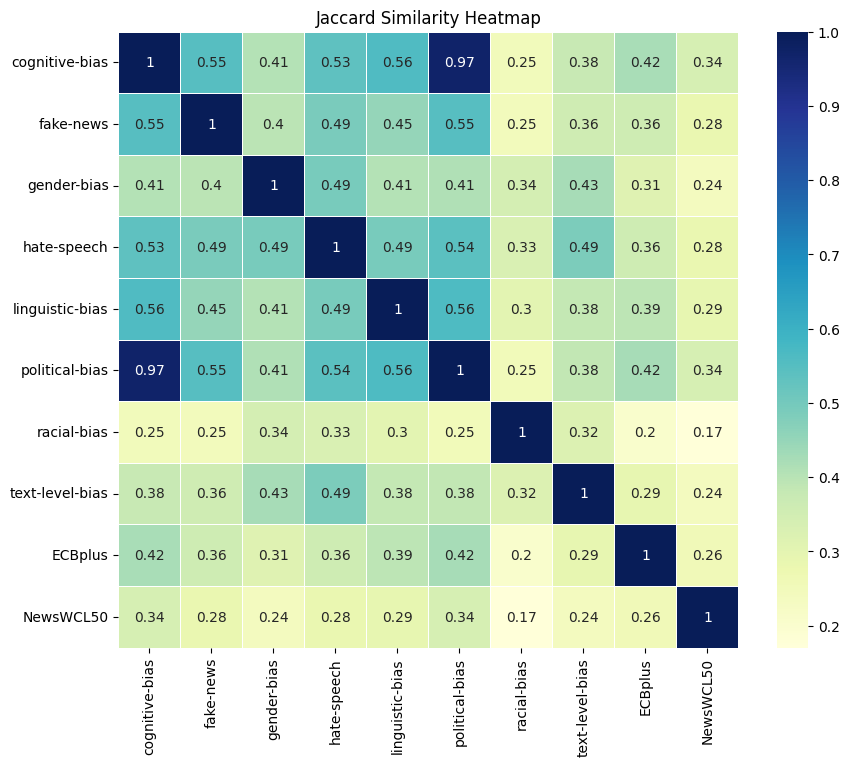

In [22]:

# Calculate Jaccard similarity for all pairs in processed_dataframes_dict
similarity_matrix = pd.DataFrame(index=processed_dataframes_dict.keys(), columns=processed_dataframes_dict.keys())

for key1, set1 in processed_dataframes_dict.items():
    for key2, set2 in processed_dataframes_dict.items():
            similarity_matrix.loc[key1, key2] = jaccard_similarity(set1, set2)

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5)
plt.title("Jaccard Similarity Heatmap")
plt.show()

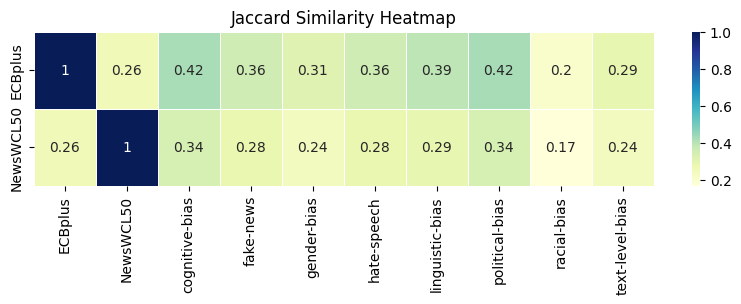

In [23]:
# Extract keys for rows and columns
rows = ['ECBplus', 'NewsWCL50']
columns = ['ECBplus', 'NewsWCL50']
columns.extend([key for key in processed_dataframes_dict if key not in rows])



# Calculate Jaccard similarity for specified pairs
similarity_matrix = pd.DataFrame(index=rows, columns=columns)

for row_key in rows:
    for col_key in columns:
        similarity_matrix.loc[row_key, col_key] = jaccard_similarity(
            processed_dataframes_dict[row_key], processed_dataframes_dict[col_key]
        )

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 2))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5, square=False)
plt.title("Jaccard Similarity Heatmap")
plt.show()

In [19]:
### Check average document size

In [24]:
# Calculate average length for each dataset
for dataset_name, dataset_data in dataframes_dict.items():
    try:
        string_list = dataset_data['text']
        average_length = sum(len(s) for s in string_list) / len(string_list)
        print(f"Average length of strings in {dataset_name}: {average_length}")

    except TypeError as e:
        print(f"Error in {dataset_name}: {e}")

Average length of strings in cognitive-bias: 233.0685998825949
Error in fake-news: object of type 'float' has no len()
Average length of strings in gender-bias: 128.2008380724334
Average length of strings in hate-speech: 270.87579694592534
Average length of strings in linguistic-bias: 283.94485896448947
Error in political-bias: object of type 'float' has no len()
Average length of strings in racial-bias: 96.61248467511238
Average length of strings in text-level-bias: 186.382457307607


In [27]:
mixed_political_cognitive= pd.concat([dataframes_dict["political-bias"], dataframes_dict["cognitive-bias"]])
mixed_political_cognitive.drop_duplicates(subset=["text"],inplace=True)
mixed_political_cognitive.drop(["id","dataset_id"],axis=1,inplace=True)
mixed_political_cognitive.columns=["text","label_bias"]

#Map labels to binary value
mixed_political_cognitive['label_bias'] = mixed_political_cognitive['label_bias'].map({'0': 0, 'False': 0, '1': 1, 'True': 1})
mixed_political_cognitive.dropna(inplace=True)

In [29]:
## Export text column only as text file
mixed_political_cognitive["text"].to_csv("dapt_political_cognitive_bias.txt", sep='\t', index=False)


In [ ]:
# Still pending exporting this dataset and the linguistic one

In [69]:
mixed_political_cognitive.to_excel("dapt_political_cognitive_dataset.xlsx",index=False)

ModuleNotFoundError: No module named 'openpyxl'